# Chem 427, Project #11: Nanoparticle size by three techniques

**Question.** Does AFM height read silica nanoparticles smaller than SEM and SAXS do, while reading gold nanoparticles correctly, by more than the combined uncertainty, and can your own particle segmentation reproduce the expert-annotated size distributions?

## Data availability

All data are public, were downloaded on 2026-11-08, and are committed in `data/` exactly as downloaded; the MD5 checksum of each zip matches the one listed on its Zenodo record. All cleaning happens in code below, and the notebook does not download anything.

| Files in `data/` | Content | Source | License |
|---|---|---|---|
| `VSL.zip` | VSL laboratory images as 2D arrays | pollen-metrology.com, *nPSize VSL images as 2D arrays*, Zenodo (2021), https://doi.org/10.5281/zenodo.5578927 | CC0 |
| `LNE1.zip`, `LNE2.zip`, `LNE3.zip` | LNE laboratory images as 2D arrays | pollen-metrology.com, *nPSize LNE images as 2D arrays*, Zenodo (2021), https://doi.org/10.5281/zenodo.5578878 | CC0 |
| `annotations.zip` | Expert particle annotations (`annotations.json`) | pollen-metrology.com, *nPSize JSON file: image annotations*, Zenodo (2021), https://doi.org/10.5281/zenodo.5577401 | CC0 |
| `nPSize*.dat` | SAXS curves | Deumer, J., Gollwitzer, C., Zenodo (2022), https://doi.org/10.5281/zenodo.5886834 | CC BY 4.0 |
| `17NRM04_D3_ValidationReport_v1.0_Accepted.pdf` | Validation report with reference sizes | Bartczak, D., Hodoroaba, V.-D., Zenodo (2022), https://doi.org/10.5281/zenodo.7016466 | CC BY 4.0 |

Accessed 2026-11-08.

## Setup and imports

The next cell imports the libraries used below: `json` and `zipfile` to read the annotations from inside their zip, NumPy, pandas and Matplotlib. It prints nothing when it works.

In [1]:
import json
import sys
import zipfile

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
from scipy import ndimage

## Parameters

Every number that encodes a scientific or statistical choice is set here, with its unit and its reason. Running this cell prints nothing.

In [2]:
ANNOTATIONS_ZIP = "data/annotations.zip"   # expert annotations, as downloaded; read from inside the zip
TECHNIQUES = ["AFM", "SEM"]                # techniques compared in the question; TEM and TSEM are not used (N4)
MATERIALS = ["01", "10"]    # nPSize01 = gold, nPSize10 = silica: the two materials in the question
MATERIAL_NAMES = {"01": "gold", "10": "silica"}   # labels for tables and figures
GOLD_SPLIT_NM = 45          # nm; gold particles below are the 30 nm population, at or above the 60 nm one.
                            # 45 nm is the midpoint of the nominal sizes, (30 + 60) / 2, and lies in the gap between them.
RNG_SEED = 427              # dimensionless; fixed so bootstrap CIs are identical on every rerun
N_BOOTSTRAP = 10_000        # resamples per bootstrap
CI_LEVEL = 0.95             # fraction; conventional two-sided confidence level
BOOTSTRAP_UNIT = "image"    # resampling unit; particles in one image share the tip or beam, calibration and
                            # background, so they err together (S14: draw whole the unit that errs together)
HIST_BIN_WIDTH_NM = {"01": 4.0, "10": 2.0}         # nm; at least one SEM pixel step, so whole-pixel sizes do not make a comb
HIST_RANGE_NM = {"01": (0, 110), "10": (30, 70)}   # nm; covers every in-scope size
OUTLIER_TRIM_FRACTION = 0.01   # fraction dropped at each end in the outlier check only; nothing is removed (N6)

AFM_MAPS_ZIP = "data/VSL.zip"        # VSL AFM height maps, as downloaded; read from inside the zip
AFM_HEADER_BYTES = 2048              # bytes before the height array in each file
AFM_MAP_SHAPE = (512, 512)           # pixels
AFM_PIXEL_NM = 3000 / 511            # nm per pixel; 3 µm scan over 512 pixels (5.87 nm/px, as in the annotations)
SEGMENT_MATERIAL = "10"              # silica: one population, and the material the question centres on

SUBSTRATE_MAX_NM = 5.0        # nm; pixels below this are substrate for the plane fit and noise estimate:
                              # far above the noise (σ ≈ 0.1 nm), far below silica tops (≈ 45 nm)
THRESHOLD_SIGMA = 5           # dimensionless; a particle pixel lies > 5 σ above the flattened substrate,
                              # so noise alone gives < 1 false pixel per 512 × 512 map
MIN_PARTICLE_AREA_PX = 170    # px; whole particles cover > 200 px, debris and noise < 140 px (B2 figure).
                              # A cut on area, not height, so the selection does not bias the height measured

rng = np.random.default_rng(RNG_SEED)

## Load the expert annotations
(S04, S05)
`annotations.json` nests laboratory → microscope → image → particle. This cell flattens it into a tidy table, `annotations`: one row per expert-annotated particle in one image, one column per variable. The columns are the laboratory, technique, material (`npsize`), image, pixel size (nm/px), AFM height (nm, AFM rows only), minimum and maximum Feret diameter (nm) and centroid (nm). Each measurement is stored as a `{unit, value}` pair, and the cell stops if any unit is not nm. Expect the table's shape (11,227 rows, 10 columns) and its first rows.

In [3]:
SIZE_FIELDS = {                                  # JSON key -> column name, all in nm
    "afm_height": "afm_height_nm",
    "minimum_feret_diameter": "feret_min_nm",
    "maximum_feret_diameter": "feret_max_nm",
}
size_columns = list(SIZE_FIELDS.values())       # nm

with zipfile.ZipFile(ANNOTATIONS_ZIP) as archive:
    raw = json.load(archive.open("annotations.json"))

rows = []
n_skipped = 0                                    # JSON entries that are not microscopes or particles
for lab in raw.values():
    for scope_key, scope in lab.items():
        if not scope_key.startswith("microscope"):   # e.g. the lab's "name"
            n_skipped += 1
            continue
        for image in scope["data"].values():
            for particle_key, particle in image["particles"].items():
                if not particle_key.startswith("particle"):   # e.g. the image's "total"
                    n_skipped += 1
                    continue
                measurements = particle["measurements"]
                for key in [*SIZE_FIELDS, "centroid"]:
                    if measurements[key]["unit"] != "nm":
                        raise ValueError(f"{key} is in {measurements[key]['unit']}, not nm")
                row = {
                    "laboratory": lab["name"],
                    "technique": scope["type"],
                    "npsize": image["npsize"],
                    "image": image["name"],
                    "pixel_size_nm": image["pixel_size"],       # nm per pixel
                    **{column: measurements[key]["value"] for key, column in SIZE_FIELDS.items()},
                    "centroid_x_nm": measurements["centroid"]["x"],
                    "centroid_y_nm": measurements["centroid"]["y"],
                }
                rows.append(row)

annotations = pd.DataFrame(rows)
annotations[size_columns] = annotations[size_columns].apply(pd.to_numeric)   # None -> NaN

print(annotations.shape)
annotations.head()

(11227, 10)


,laboratory,technique,npsize,image,pixel_size_nm,afm_height_nm,feret_min_nm,feret_max_nm,centroid_x_nm,centroid_y_nm
0,BAM,SEM,01,2103076.h5,1.836,NaN,62.853654,64.151904,2610.745383,991.646640
1,BAM,SEM,01,2103076.h5,1.836,NaN,62.424000,66.096000,2152.830801,920.426055
2,BAM,SEM,01,2103076.h5,1.836,NaN,66.096000,67.932000,1993.800524,769.081002
3,BAM,SEM,01,2103076.h5,1.836,NaN,64.260000,64.260000,2635.631341,731.770331
4,BAM,SEM,01,2103076.h5,1.836,NaN,62.424000,62.424000,1553.457821,1155.788222


## Problems found on loading

This cell keeps the groups in the question (gold and silica, AFM and SEM) and checks them for problems that could bias a size comparison. It removes nothing. The checks: the particles, images and pixel sizes per group; missing AFM heights, where the count should equal the number of SEM rows, since only AFM measures height, with none missing on AFM rows; impossible sizes; the same particle twice (same image and centroid); and JSON entries the loader skipped. Expect one line per check.

In [4]:
in_scope = annotations[annotations["npsize"].isin(MATERIALS) & annotations["technique"].isin(TECHNIQUES)]
print(f"{len(in_scope)} of {len(annotations)} particles in scope")
for (material, technique), rows_g in in_scope.groupby(["npsize", "technique"]):
    pixel_sizes = ", ".join(f"{p:.2f}" for p in sorted(rows_g["pixel_size_nm"].unique()))
    print(f"  nPSize{material} {technique}: {len(rows_g)} particles in {rows_g['image'].nunique()} images, "
          f"pixel size {pixel_sizes} nm/px")

is_sem = in_scope["technique"] == "SEM"
impossible = (in_scope[size_columns] <= 0).any(axis=1) | (in_scope["feret_min_nm"] > in_scope["feret_max_nm"])
same_particle = in_scope.duplicated(subset=["image", "centroid_x_nm", "centroid_y_nm"])
print(f"Missing AFM height: {in_scope.loc[is_sem, 'afm_height_nm'].isna().sum()} on {is_sem.sum()} SEM rows, "
      f"{in_scope.loc[~is_sem, 'afm_height_nm'].isna().sum()} on AFM rows")
print(f"Impossible sizes (<= 0 nm, or min Feret > max Feret): {impossible.sum()}")
print(f"Same particle twice (same image and centroid): {same_particle.sum()}")
print(f"JSON entries skipped by the loader: {n_skipped}")

1267 of 11227 particles in scope
  nPSize01 AFM: 620 particles in 20 images, pixel size 5.87 nm/px
  nPSize01 SEM: 318 particles in 16 images, pixel size 1.40, 1.84 nm/px
  nPSize10 AFM: 42 particles in 10 images, pixel size 5.87 nm/px
  nPSize10 SEM: 287 particles in 13 images, pixel size 0.92, 1.86 nm/px
Missing AFM height: 605 on 605 SEM rows, 0 on AFM rows
Impossible sizes (<= 0 nm, or min Feret > max Feret): 0
Same particle twice (same image and centroid): 0
JSON entries skipped by the loader: 558


1. **AFM height exists only for AFM.** It is missing on all 605 SEM rows and on 0 of 662 AFM rows, as expected, since only AFM measures height. Kept as NaN; SEM is compared by its minimum Feret diameter.
2. **Pixel size differs between labs:** 1.40 and 1.84 nm/px for gold SEM, 0.92 and 1.86 nm/px for silica SEM, against 5.87 nm/px for all AFM. Kept, since every size is already in nm; the analysis resamples SEM within each laboratory.
3. **Silica AFM is a small group:** 42 particles in 10 images, against 287 by SEM. Kept; its uncertainty is carried by the image bootstrap.
4. **Checked, none found:** 0 impossible sizes and 0 particles counted twice.
5. **Format quirks:** 558 JSON entries that are not microscopes or particles (each laboratory's name and each image's total) are skipped by the loader.
6. **Outliers:** kept; the medians are unchanged without the extremes (N6; checked after the histogram below).
7. **Not used:** the 2,318 TEM and 826 TSEM particles (N4) and the 6,816 AFM and SEM particles of the other nPSize materials, since the question asks only about gold (nPSize01) and silica (nPSize10). The 1,267 particles kept are counted above.
8. **AFM height maps are HDF5 files, but `h5py` is not in the course environment:** each of the 10 silica maps in `VSL.zip` is a 2,048-byte header followed by 512 × 512 heights stored as little-endian float64 (2,099,200 bytes per file). Read as raw bytes after the header (B1); the printed substrate medians (−0.17 to −0.08 nm) and maximum heights (43.9 to 52.5 nm) confirm the read, since a wrong offset or byte order gives values near 10³⁰⁷ nm.

## Explore

This cell gives each particle one size, `size_nm`: the AFM height for AFM and the minimum Feret diameter for SEM (N1). It then summarises each group: AFM, SEM pooled (BAM + LNE) and SEM per lab, for each population. Median and IQR are shown because the analysis is median-based, and the mean beside the median shows skew. Gold is split at `GOLD_SPLIT_NM` into its two populations (N3). Expect an 11-row table in nm, with silica AFM near 44 nm and SEM near 48 nm.

In [5]:
in_scope = in_scope.assign(size_nm=in_scope["afm_height_nm"].where(in_scope["technique"] == "AFM",
                                                                   in_scope["feret_min_nm"]))   # nm: AFM height, SEM min Feret (N1)
in_scope["population"] = np.where(in_scope["npsize"] == "10", "silica",
                                  np.where(in_scope["size_nm"] < GOLD_SPLIT_NM, "gold 30 nm", "gold 60 nm"))   # N3
POPULATIONS = ["silica", "gold 30 nm", "gold 60 nm"]

summary_rows = []
for population in POPULATIONS:
    rows_p = in_scope[in_scope["population"] == population]
    sem = rows_p[rows_p["technique"] == "SEM"]
    groups = {
        "AFM": rows_p[rows_p["technique"] == "AFM"],
        "SEM pooled": sem,
        "  SEM BAM": sem[sem["laboratory"] == "BAM"],
        "  SEM LNE": sem[sem["laboratory"] == "LNE"],
    }
    for label, rows_g in groups.items():
        if rows_g.empty:                         # BAM imaged no 30 nm gold
            continue
        q1, median, q3 = rows_g["size_nm"].quantile([0.25, 0.50, 0.75])
        summary_rows.append({"population": population, "group": label,
                             "n particles": len(rows_g), "n images": rows_g["image"].nunique(),
                             "median": median, "IQR": q3 - q1, "mean": rows_g["size_nm"].mean()})

pd.DataFrame(summary_rows).set_index(["population", "group"]).round(1)   # sizes in nm

n particles  n images  median  IQR  mean
population group                                               
silica     AFM                  42        10    43.7  3.0  43.7
           SEM pooled          287        13    47.7  2.7  47.7
             SEM BAM            96         6    46.9  3.7  47.2
             SEM LNE           191         7    47.9  2.7  47.9
gold 30 nm AFM                 324        20    28.7  4.3  28.7
           SEM pooled          122        10    30.7  4.2  30.3
             SEM LNE           122        10    30.7  4.2  30.3
gold 60 nm AFM                 296        20    58.7  7.7  59.7
           SEM pooled          196        16    61.4  8.2  62.1
             SEM BAM            90         6    64.3  6.2  65.2
             SEM LNE           106        10    60.0  5.6  59.5

**Table 1:** For silica, the AFM median height is 43.7 nm, and the SEM median minimum Feret diameter is 47.7 nm. For gold (30 nm), the AFM median height is 28.7 nm, and the SEM median minimum Feret diameter is 30.7 nm. For Gold (60 nm), the AFM median height is 58.7 nm, and the SEM median minimum Feret diameter 61.4 nm. The SEM median is the larger value across all three populations. For silica, BAM and LNE agree within 1 nm.  For gold (60 nm) the BAM and LNE values differ by 4.3 nm, which is greater than the AFM/SEM split. For gold (30 nm), only LNE values are available.

This figure compares the shape of the AFM and SEM size distributions, one panel per material. The curves are probability densities, because the groups differ in size (42 to 620 particles), and each series has its own line style and marker. The dotted line on the gold panel is `GOLD_SPLIT_NM`. Expect two modes near 30 and 60 nm for gold, and one narrow peak near 45 to 50 nm for silica.

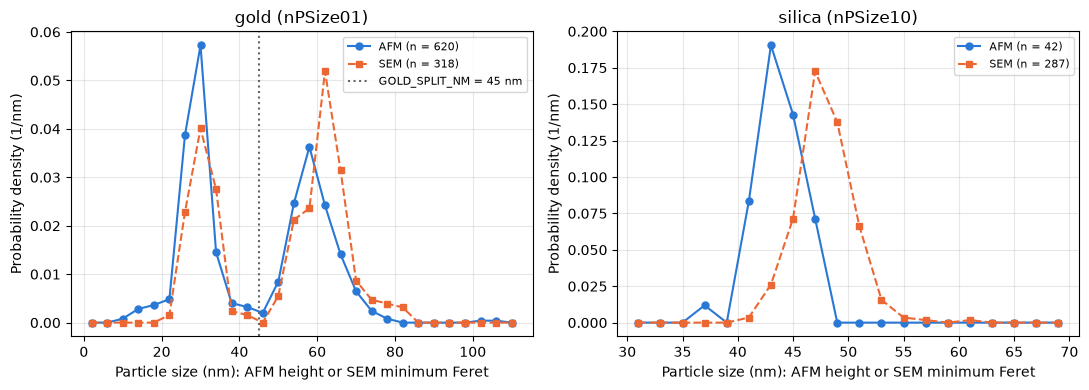

In [6]:
SERIES_STYLE = {"AFM": ("#2a78d6", "-", "o"), "SEM": ("#eb6834", "--", "s")}   # technique -> colour, line, marker

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, material in zip(axes, MATERIALS):
    rows_m = in_scope[in_scope["npsize"] == material]
    low, high = HIST_RANGE_NM[material]
    bin_edges = np.arange(low, high + HIST_BIN_WIDTH_NM[material], HIST_BIN_WIDTH_NM[material])   # nm
    bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2                                            # nm
    for technique, (colour, linestyle, marker) in SERIES_STYLE.items():
        sizes = rows_m.loc[rows_m["technique"] == technique, "size_nm"]
        density, _ = np.histogram(sizes, bins=bin_edges, density=True)                           # 1/nm
        ax.plot(bin_centers, density, color=colour, linestyle=linestyle, marker=marker,
                markersize=5, label=f"{technique} (n = {len(sizes)})")
    if material == "01":
        ax.axvline(GOLD_SPLIT_NM, color="0.4", linestyle=":", label=f"GOLD_SPLIT_NM = {GOLD_SPLIT_NM} nm")
    ax.set_title(f"{MATERIAL_NAMES[material]} (nPSize{material})")
    ax.set_xlabel("Particle size (nm): AFM height or SEM minimum Feret")
    ax.set_ylabel("Probability density (1/nm)")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

**Figure 1:** The gold distribution is bimodal, with peaks centered around 30 nm and 60 nm for both AFM and SEM, the silica distribution is centered around 44 nm for AFM and 48 nm for SEM. 

Note: This figure showed that the gold distribution is bimodal, and as a result the code for the explore table was edited to reflect the population medians rather than the pooled median. Before, the gold AFM median was 37.9 nm and the SEM median was 56.9 nm.

This cell checks whether the most extreme particles could move a result. It prints each group's median with all particles and with `OUTLIER_TRIM_FRACTION`, and at least one particle, dropped at each end, plus its lowest and highest size. No particle is removed (N6). Expect medians that are unchanged at 0.1 nm.

In [7]:
for (population, technique), rows_g in in_scope.groupby(["population", "technique"]):
    sizes = np.sort(rows_g["size_nm"].to_numpy())                         # nm
    n_trim = max(1, int(OUTLIER_TRIM_FRACTION * len(sizes)))
    trimmed = sizes[n_trim:len(sizes) - n_trim]
    print(f"{population} {technique}: median {np.median(sizes):.1f} nm, {np.median(trimmed):.1f} nm without "
          f"{n_trim} at each end; range {sizes[0]:.1f} to {sizes[-1]:.1f} nm (n = {len(sizes)})")

gold 30 nm AFM: median 28.7 nm, 28.7 nm without 3 at each end; range 11.4 to 44.6 nm (n = 324)
gold 30 nm SEM: median 30.7 nm, 30.7 nm without 1 at each end; range 22.1 to 41.9 nm (n = 122)
gold 60 nm AFM: median 58.7 nm, 58.7 nm without 2 at each end; range 45.7 to 105.2 nm (n = 296)
gold 60 nm SEM: median 61.4 nm, 61.4 nm without 1 at each end; range 48.9 to 82.6 nm (n = 196)
silica AFM: median 43.7 nm, 43.7 nm without 1 at each end; range 36.3 to 47.2 nm (n = 42)
silica SEM: median 47.7 nm, 47.7 nm without 2 at each end; range 41.3 to 60.6 nm (n = 287)


## Part A: does AFM read silica smaller, and gold correctly?

*Question parts 1–4: AFM against SEM and SAXS, and against the combined uncertainty.*

### A1–A2. AFM − SEM for silica and gold

(S14) This cell compares the median AFM height with the median SEM minimum Feret (N1) for silica and for each gold population (N3), and gives the difference with a bootstrap 95% CI. Each resample draws whole images, within each laboratory for SEM (N2, N5). AFM and SEM are resampled independently, and the difference is taken resample by resample. The same bootstrap drawing single particles is shown beside it as the named alternative (N5). Expect two printed lines per population, then a figure with one row per population and a dashed line at zero, where AFM and SEM agree.

**Why this method:** The median is used because the sizes have long tails (gold 60 nm AFM: 45.7 to 105.2 nm around a 58.7 nm median), and the bootstrap gives its CI without assuming a distribution. Whole images are resampled because particles in one image share a tip, a calibration and a background. That matters most for silica AFM, with only 42 particles in 10 images. SEM is resampled within each laboratory because BAM and LNE differ in pixel size and median (gold 60 nm: 64.3 vs 60.0 nm).


silica: AFM 43.72 nm (n = 42, 10 images), SEM 47.74 nm (n = 287, 13 images, BAM + LNE); AFM − SEM = -4.01 nm


    95% CI by image: -4.78 to -2.68 nm


    95% CI by particle: -5.03 to -2.47 nm
gold 30 nm: AFM 28.70 nm (n = 324, 20 images), SEM 30.71 nm (n = 122, 10 images, LNE); AFM − SEM = -2.01 nm


    95% CI by image: -2.35 to -0.99 nm


    95% CI by particle: -2.30 to -0.53 nm
gold 60 nm: AFM 58.66 nm (n = 296, 20 images), SEM 61.42 nm (n = 196, 16 images, BAM + LNE); AFM − SEM = -2.76 nm


    95% CI by image: -4.10 to -1.54 nm


    95% CI by particle: -4.02 to -2.09 nm


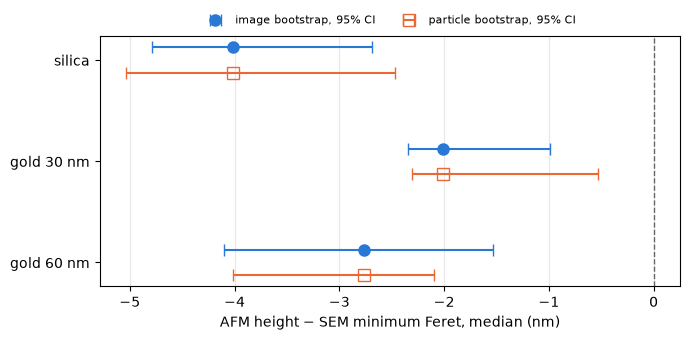

In [8]:
def bootstrap_medians(rows, unit):
    """Medians (nm) of N_BOOTSTRAP resamples drawing whole units (images or particles) within each laboratory."""
    strata = []
    for _, rows_lab in rows.groupby("laboratory"):
        by = rows_lab["image"] if unit == "image" else rows_lab.index
        strata.append([rows_unit["size_nm"].to_numpy() for _, rows_unit in rows_lab.groupby(by)])
    medians = np.empty(N_BOOTSTRAP)
    for b in range(N_BOOTSTRAP):
        drawn = [units[i] for units in strata for i in rng.integers(0, len(units), len(units))]
        medians[b] = np.median(np.concatenate(drawn))
    return medians


UNIT_STYLE = {"image": ("#2a78d6", "o", "full", 0.0), "particle": ("#eb6834", "s", "none", 0.25)}   # N5
tail = (1 - CI_LEVEL) / 2

fig, ax = plt.subplots(figsize=(7, 3.5))
for y, population in enumerate(POPULATIONS):
    rows_p = in_scope[in_scope["population"] == population]
    afm, sem = rows_p[rows_p["technique"] == "AFM"], rows_p[rows_p["technique"] == "SEM"]
    difference = afm["size_nm"].median() - sem["size_nm"].median()                        # nm
    print(f"{population}: AFM {afm['size_nm'].median():.2f} nm (n = {len(afm)}, {afm['image'].nunique()} images), "
          f"SEM {sem['size_nm'].median():.2f} nm (n = {len(sem)}, {sem['image'].nunique()} images, "
          f"{' + '.join(sorted(sem['laboratory'].unique()))}); AFM − SEM = {difference:.2f} nm")
    for unit, (colour, marker, fill, offset) in UNIT_STYLE.items():
        low, high = np.quantile(bootstrap_medians(afm, unit) - bootstrap_medians(sem, unit), [tail, 1 - tail])
        print(f"    {CI_LEVEL:.0%} CI by {unit}: {low:.2f} to {high:.2f} nm")
        ax.errorbar(difference, y + offset, xerr=[[difference - low], [high - difference]], fmt=marker,
                    fillstyle=fill, color=colour, markersize=8, capsize=4,
                    label=f"{unit} bootstrap, {CI_LEVEL:.0%} CI" if y == 0 else None)
ax.axvline(0, color="0.4", linestyle="--", linewidth=1)
ax.set_yticks(np.arange(len(POPULATIONS)) + 0.125, POPULATIONS)
ax.invert_yaxis()
ax.set_xlabel("AFM height − SEM minimum Feret, median (nm)")
ax.grid(axis="x", alpha=0.3)
ax.legend(fontsize=8, loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2, frameon=False)
fig.tight_layout()
plt.show()

**Figure 2:** The image bootstrap gives a more narrow confidence interval than the particle bootstrap for both silica and gold (30 nm), but a wider CI for gold (60 nm), every CI excludes 0.

## Part B: can my own segmentation reproduce the experts?


### B1. Load the AFM height maps

This cell reads the silica AFM height maps from `VSL.zip`. Each file is a 2,048-byte header followed by 512 × 512 heights in nm, stored as little-endian float64. It prints one line to confirm the bytes were read correctly. Expect 10 maps with substrate medians near 0 nm and maximum heights near 45 nm; a wrong offset or byte order would give values far outside this range.

In [9]:
with zipfile.ZipFile(AFM_MAPS_ZIP) as archive:
    map_names = sorted(name for name in archive.namelist() if f"npsize_{SEGMENT_MATERIAL}_" in name)
    afm_maps = {name: np.frombuffer(archive.read(name), dtype="<f8", offset=AFM_HEADER_BYTES).reshape(AFM_MAP_SHAPE)
                for name in map_names}                                  # nm

print(f"{len(afm_maps)} maps of nPSize{SEGMENT_MATERIAL}; substrate medians "
      f"{min(np.median(m) for m in afm_maps.values()):.2f} to {max(np.median(m) for m in afm_maps.values()):.2f} nm, "
      f"maximum heights {min(m.max() for m in afm_maps.values()):.1f} to {max(m.max() for m in afm_maps.values()):.1f} nm")

10 maps of nPSize10; substrate medians -0.17 to -0.08 nm, maximum heights 43.9 to 52.5 nm


### B2. Flatten and segment

The silica particles stand far above a flat, quiet substrate, σ is 0.10 to 0.12 nm against particle heights of about 44 nm, roughly 400 σ. For each map, this cell fits a plane to the substrate (pixels below `SUBSTRATE_MAX_NM`) and subtracts it, then estimates the substrate noise σ. It labels connected regions more than `THRESHOLD_SIGMA` × σ above the substrate, and keeps those of at least `MIN_PARTICLE_AREA_PX` that do not touch the map edge, where a particle may be cut off. It prints the noise, the number of objects and particles, and the particles per map against the experts' count. The figure plots every object's area against its height, to show the size cut separates particles from debris. Expect about 40 particles near 45 nm, well separated from small, low objects.

Substrate noise σ: 0.10 to 0.12 nm; threshold 5 σ
531 objects above threshold, 39 kept as whole particles (6 large ones dropped at the edge)
Particles per map, mine / experts: 4/5, 6/6, 8/8, 4/4, 3/5, 3/3, 2/2, 4/4, 2/2, 3/3


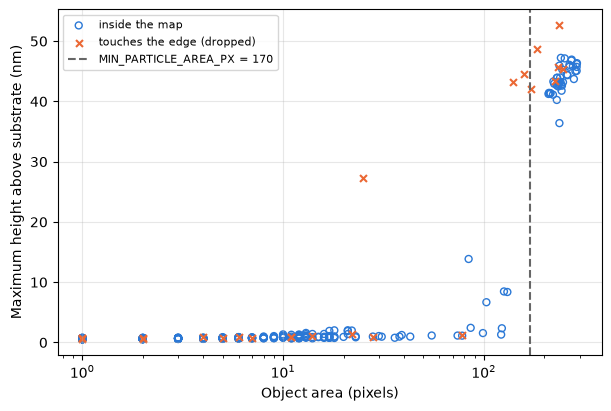

In [10]:
def flatten(height_map):
    """Subtract a plane fitted to the substrate pixels; return the flattened map (nm) and the substrate noise σ (nm)."""
    rows_px, cols_px = np.indices(height_map.shape)
    substrate = height_map < SUBSTRATE_MAX_NM
    design = np.column_stack([np.ones(substrate.sum()), cols_px[substrate], rows_px[substrate]])
    coefficients, *_ = np.linalg.lstsq(design, height_map[substrate], rcond=None)
    flat = height_map - (coefficients[0] + coefficients[1] * cols_px + coefficients[2] * rows_px)       # nm
    residual = flat[substrate]
    sigma = 1.4826 * np.median(np.abs(residual - np.median(residual)))   # nm; robust σ from the MAD
    return flat, sigma


object_rows = []
for name, height_map in afm_maps.items():
    flat, sigma = flatten(height_map)
    labels, n_labels = ndimage.label(flat > THRESHOLD_SIGMA * sigma)
    label_ids = np.arange(1, n_labels + 1)
    edge_ids = np.unique(np.concatenate([labels[0], labels[-1], labels[:, 0], labels[:, -1]]))
    areas = ndimage.sum_labels(np.ones_like(labels), labels, label_ids)                # px
    max_heights = ndimage.maximum(flat, labels, label_ids)                             # nm
    for label_id, area, max_height in zip(label_ids, areas, max_heights):
        object_rows.append({"image": name, "sigma_nm": sigma, "area_px": area, "max_height_nm": max_height,
                            "touches_edge": label_id in edge_ids})
objects = pd.DataFrame(object_rows)
segmented = objects[(objects["area_px"] >= MIN_PARTICLE_AREA_PX) & ~objects["touches_edge"]].copy()

sigmas = objects.groupby("image")["sigma_nm"].first()                                  # nm
print(f"Substrate noise σ: {sigmas.min():.2f} to {sigmas.max():.2f} nm; threshold {THRESHOLD_SIGMA} σ")
print(f"{len(objects)} objects above threshold, {len(segmented)} kept as whole particles "
      f"({(objects['touches_edge'] & (objects['area_px'] >= MIN_PARTICLE_AREA_PX)).sum()} large ones dropped at the edge)")
expert_counts = (in_scope[(in_scope["npsize"] == SEGMENT_MATERIAL) & (in_scope["technique"] == "AFM")]
                 .groupby("image").size().reindex(map_names, fill_value=0))
mine_counts = segmented.groupby("image").size().reindex(map_names, fill_value=0)
print("Particles per map, mine / experts: " + ", ".join(f"{m}/{e}" for m, e in zip(mine_counts, expert_counts)))

inside, at_edge = objects[~objects["touches_edge"]], objects[objects["touches_edge"]]
fig, ax = plt.subplots(figsize=(6, 4), layout="constrained")
ax.scatter(inside["area_px"], inside["max_height_nm"], marker="o", facecolors="none", edgecolors="#2a78d6",
           s=25, label="inside the map")
ax.scatter(at_edge["area_px"], at_edge["max_height_nm"], marker="x", color="#eb6834",
           s=25, label="touches the edge (dropped)")
ax.axvline(MIN_PARTICLE_AREA_PX, color="0.4", linestyle="--", label=f"MIN_PARTICLE_AREA_PX = {MIN_PARTICLE_AREA_PX}")
ax.set_xscale("log")
ax.set_xlabel("Object area (pixels)")
ax.set_ylabel("Maximum height above substrate (nm)")
ax.grid(alpha=0.3)
ax.legend(fontsize=8)
plt.show()

**Figure 3:** This figure plots every object's area vs its maximum height, a dashed line shows our minimum particle area, where everything below is counted as debris/noise and everything above that does not touch the edge is counted as a particle. In total, we keep 39 particles, which are well separated from the noise.

### B3. Particle heights

This cell takes each segmented particle's maximum height as its size, the AFM measure of a sphere's diameter, and reports the median with a 95% bootstrap CI, drawing whole maps (N5). The experts' heights for the same 10 maps are shown beside it for comparison. Expect a median near the experts' 43.7 nm. A value near SEM's 47.7 nm, or below 40 nm, would point to a flattening or threshold problem.

my segmentation: median 43.72 nm, 95% CI 43.19 to 44.45 nm (n = 39 particles, 10 maps)
expert annotation: median 43.72 nm, 95% CI 43.14 to 44.31 nm (n = 42 particles, 10 maps)


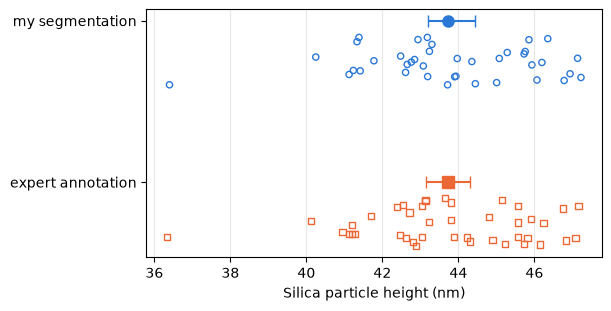

In [11]:
height_sets = {
    "my segmentation": segmented.assign(laboratory="VSL", size_nm=segmented["max_height_nm"]),
    "expert annotation": in_scope[(in_scope["npsize"] == SEGMENT_MATERIAL) & (in_scope["technique"] == "AFM")],
}
SET_STYLE = {"my segmentation": ("#2a78d6", "o"), "expert annotation": ("#eb6834", "s")}   # colour, marker

fig, ax = plt.subplots(figsize=(6, 3), layout="constrained")
for y, (label, rows_s) in enumerate(height_sets.items()):
    median = rows_s["size_nm"].median()                                                    # nm
    low, high = np.quantile(bootstrap_medians(rows_s, "image"), [tail, 1 - tail])          # nm
    print(f"{label}: median {median:.2f} nm, {CI_LEVEL:.0%} CI {low:.2f} to {high:.2f} nm "
          f"(n = {len(rows_s)} particles, {rows_s['image'].nunique()} maps)")
    colour, marker = SET_STYLE[label]
    jitter = rng.uniform(-0.15, 0.15, len(rows_s))                                         # display only
    ax.scatter(rows_s["size_nm"], y + 0.25 + jitter, marker=marker, facecolors="none", edgecolors=colour, s=20)
    ax.errorbar(median, y, xerr=[[median - low], [high - median]], fmt=marker, color=colour,
                markersize=8, capsize=4)
ax.set_yticks(range(len(height_sets)), list(height_sets))
ax.invert_yaxis()
ax.set_xlabel("Silica particle height (nm)")
ax.grid(axis="x", alpha=0.3)
plt.show()

**Figure 4:** My segmentation gives a median silica particle height of 43.72 nm, identical to the expert value. My 95% CI was 43.19 to 44.45 nm, with n=39, the expert's 95% CI was 43.14 to 44.31 nm, with n = 42.

## Next steps

*What these data cannot answer, and the assumption checked next and how.* 
- While these data can answer if AFM height reads silica nanoparticles smaller than SEM and SAXS, it cannot provide any information pertaining to why it does.  
- Cell B3 assumes that the expert's afm_height measures the height of each particle's highest pixel above the substrate plane, the same measure I use, so they can be directly compared. This is the assumption I will check next, by matching expert particles to my own segmented particles by their centroids on the same map. I will compute the difference between the height values for each matched particle. A consistent offset would mean that the expert data uses a different measure for afm_height. This is planned in task 010, for after the draft.


*To add for the final:* 
- *A3. SAXS: the report's SAXS size for each material, compared with AFM (background check set aside in `archive/saxs-background-check.ipynb`).*
- *A4. Combined uncertainty: sampling plus calibration uncertainty, combined as √(u₁² + u₂²); is each difference larger?*
- *B4. Compare with the experts: my heights against the experts' for the same particles.*

## Conclusion

*To do (final): the answer to each part of the question, with uncertainty and limits.*

## Environment

This cell prints the Python version and the versions of the packages used above, so the results can be reproduced. Expect Python 3.14 and the versions locked in `uv.lock`.

In [12]:
print(f"Python {sys.version.split()[0]}")
for module in (np, pd, matplotlib, scipy):
    print(f"{module.__name__} {module.__version__}")

Python 3.14.6
numpy 2.5.3
pandas 3.0.6
matplotlib 3.11.2
scipy 1.18.1
